In [1]:
from pathlib import Path
PROJECT_ROOT = Path.cwd().parents[1]
DATASET_DIR = PROJECT_ROOT/"Dataset"
MODEL_DIR = PROJECT_ROOT/"models"
IR_DIR = PROJECT_ROOT/"Pz and Sz"
FIG_DIR = PROJECT_ROOT / "figs" / "causality"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print(PROJECT_ROOT)
print(DATASET_DIR)
print(MODEL_DIR)
print(FIG_DIR)
# Folder_name_list_of_dataset = ['Synthesized_Dataset/Training_data', 'Synthesized_Dataset/Validate_data', 'Synthesized_Dataset/Testing_data']
# Folder_name_list_of_dataset = [DATASET_DIR/i for i in Folder_name_list_of_dataset]
# File_sheet = "Hard_Index.csv"
# MODEL_PTH = MODEL_DIR/"M6_res_Synthetic.pth"

/home/rkobayashi/anc/GFANC-custom
/home/rkobayashi/anc/GFANC-custom/Dataset
/home/rkobayashi/anc/GFANC-custom/models
/home/rkobayashi/anc/GFANC-custom/figs/causality


In [2]:

import matplotlib.pyplot as plt
import numpy as np
import torch

from common.loading_real_wave_noise import loading_real_wave_noise
from common.Reading_path_test import loading_paths_from_MAT
from data.Disturbance_generation import Disturbance_generation_from_real_noise
from fxlms.FxLMS_algorithm_v2 import FxLMS, train_fxlms_algorithm, Noisy_FxLMS, train_fxlms_algorithm_for_noisy_ref
from gfanc.Control_filter_selection_pre_now import Control_filter_selection_pre_now
from gfanc.Fixed_filter_noise_cancellation_subfilters import Fixed_filter_controller

print(torch.cuda.is_available())

True


In [3]:
# Loading real noises
mdict = {}
fs = 16000
StepSize = 0.0001
sound_name = 'Helicopter'
waveform, resample_rate = loading_real_wave_noise(folde_name=PROJECT_ROOT/'Real Noise Examples/', sound_name=sound_name+'.wav')
waveform = waveform[0].unsqueeze(0)

path_name: Dongyuan


[========================================================================] 100%


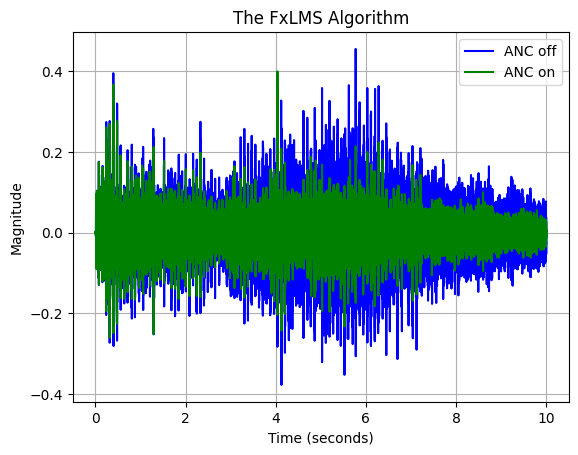

path_name: Dongyuan


[========================================================================] 100%


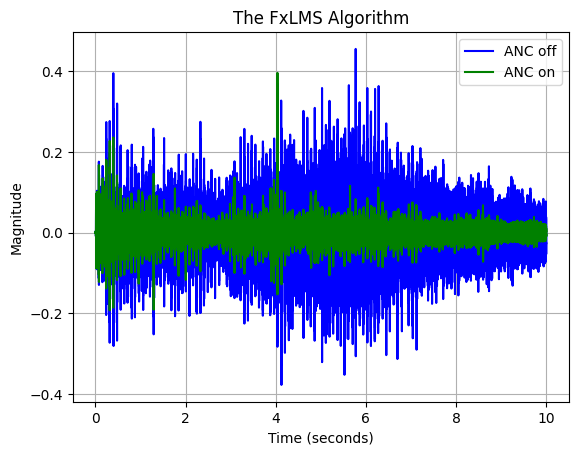

In [4]:
# FxLMS
delay = -128
ErrorFxLMSs = {}
StepSizes = [ StepSize * 10 ** i for i in range(2)]
for stepsize in StepSizes:
    ErrorTemp = {}
    # Loading path
    if delay == -128:
        subfolder = "Dongyuan"
    else:
        subfolder = "Secondary_path_delay_" + str(delay) + "samples"
    Pri_path, Secon_path = loading_paths_from_MAT(folder=IR_DIR, subfolder=subfolder, Pri_path_file_name='Primary_path.mat', Sec_path_file_name='Secondary_path.mat')
    Dis, Fx, Re = Disturbance_generation_from_real_noise(fs=fs, Repet=0, wave_form=waveform, Pri_path=Pri_path, Sec_path=Secon_path)
    # GFANC: combining previous and present frame to predict the next
    print(f"path_name: {subfolder}")
    controller = Noisy_FxLMS(Len=1024) # 1024 is the same size of coeffient vector of fixed-filter
    ErrorFxLMS = train_fxlms_algorithm_for_noisy_ref(Model=controller, Ref=Re, Disturbance=Dis, Secondary_path=torch.tensor(Secon_path, dtype=torch.float32), filter_len=1024, Stepsize=stepsize) # torch.Size([320000])
    Time = np.arange(len(Dis))*(1/fs)
    plt.title('The FxLMS Algorithm')
    plt.plot(Time, Dis, color='blue', label='ANC off')
    plt.plot(Time, ErrorFxLMS, color='green', label='ANC on')
    plt.ylabel('Magnitude')
    plt.xlabel('Time (seconds)')
    plt.legend()
    plt.grid()
    plt.savefig(FIG_DIR/(sound_name + "_aircraft_" + str(delay) + 'FxLMS.png'), dpi=600, bbox_inches='tight', pad_inches=0)
    plt.show()

